SECTION 3.1 — Diversity examples
Community A: (np.float64(1.0296530140645737), np.float64(0.62))
Community B: (np.float64(0.9404479886553263), np.float64(0.4800000000000001))

SECTION 3.2 — Data loaded
Number of specimens: 65
Column names:
['Initials', 'Habitat', 'Lat_long', 'Class_AI', 'Order_AI', 'Family_AI', 'Genus_AI', 'Species_AI', 'Lowest_ID_AI', 'Lowest_rank_AI', 'Class_Morphology', 'Order_Morphology', 'Family_Morphology', 'Genus_Morphology', 'Species_Morphology', 'Lowest_ID_Morph', 'Lowest_rank_Morph', 'Class_DNA', 'Order_DNA', 'Family_DNA', 'Genus_DNA', 'Species_DNA', 'Lowest_ID_DNA', 'Lowest_rank_DNA', 'BLAST_ID', 'BLAST_percentID', 'BLAST_Evalue', 'BLAST_coverage', 'BLAST_accession', 'BOLD_ID', 'BOLD_PID', 'BOLD_confidence']

Habitat counts:
Habitat
Ashworth Trees      16
Murchison           12
Nucleus Mound       11
Secret Garden       11
Behind Ashworth     10
Ashworth Meadows     5
Name: count, dtype: int64[pyarrow]

Morphology family counts:
Family_Morphology
Acanthosoma

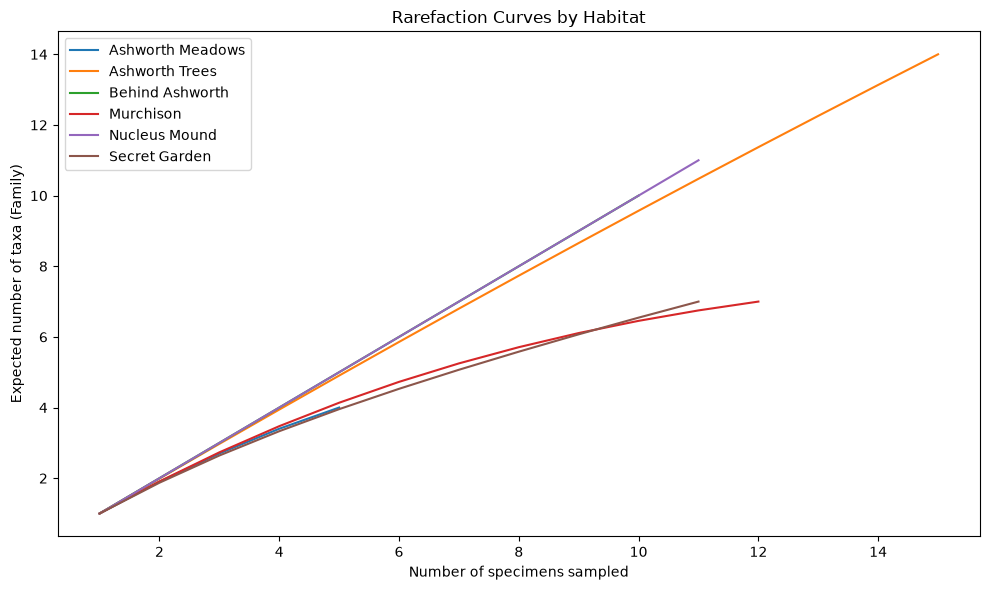

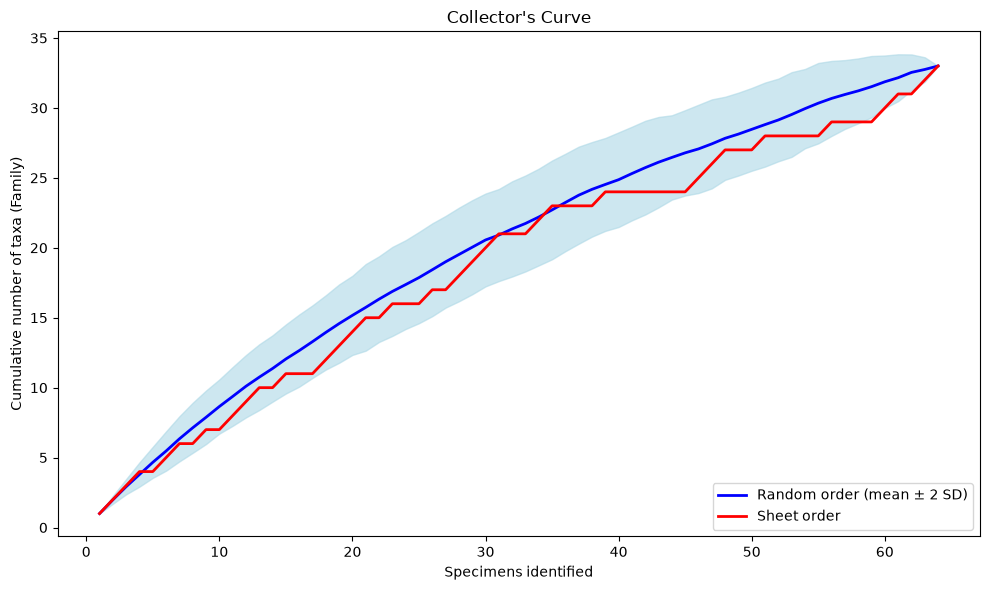


SECTION 3.6 — Richness estimation
Observed richness: 33
Singletons: 19
Doubletons: 6
Estimated richness (Chao1): 63.08
Estimated proportion detected: 52.3 %

Analysis complete!
Results saved as CSV files.


In [1]:

# ============================================================
# ADE3 COMPUTER PRACTICAL 2026
# From Sequence to Diversity
# Python version of the original R practical
# ============================================================

# Install these packages if needed:
# pip install pandas numpy scipy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gammaln
from pathlib import Path


# ============================================================
# SECTION 3.1 — SHANNON AND SIMPSON DIVERSITY
# ============================================================

def diversity(counts):
    counts = np.asarray(counts, dtype=float)
    counts = counts[counts > 0]

    if len(counts) == 0:
        return np.nan, np.nan

    p = counts / counts.sum()

    shannon = -np.sum(p * np.log(p))
    simpson = 1 - np.sum(p ** 2)

    return shannon, simpson


# Community A: 5, 3, 2
# Community B: 7, 1, 1, 1

A = [5, 3, 2]
B = [7, 1, 1, 1]

print("SECTION 3.1 — Diversity examples")
print("Community A:", diversity(A))
print("Community B:", diversity(B))


# ============================================================
# SECTION 3.2 — LOAD AND CLEAN CLASS DATA
# ============================================================

# Change this path if your CSV is somewhere else.
file_path = "ADE_class_data_frozen.csv"

arth = pd.read_csv(
    file_path,
    dtype="string",
    keep_default_na=False
)

# Remove unnamed empty columns.
arth = arth.loc[
    :, ~arth.columns.str.startswith("Unnamed:")
]

# Remove extra spaces and standardise missing values.
for col in arth.columns:
    arth[col] = (
        arth[col]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

arth = arth.replace(
    r"(?i)^(?:|NA|-|n/a|No clear ID)$",
    pd.NA,
    regex=True
)

# Remove blank specimen rows.
arth = arth.dropna(subset=["Initials"]).copy()

print("\nSECTION 3.2 — Data loaded")
print("Number of specimens:", len(arth))
print("Column names:")
print(arth.columns.tolist())


# ============================================================
# CLEAN TAXONOMY AND HABITAT NAMES
# ============================================================

taxonomic_columns = [
    col for col in arth.columns
    if col.startswith(("Class_", "Order_", "Family_", "Genus_"))
]

# Standardise capitalisation.
for col in taxonomic_columns + ["Habitat"]:
    arth[col] = arth[col].str.title()


# Corrections from the original R practical.
fixes = {

    # Class
    "Insects": "Insecta",
    "Insect": "Insecta",
    "Pancrustacea": "Insecta",
    "Malacosraca": "Malacostraca",

    # Order
    "Harvestmen": "Opiliones",
    "Opilones": "Opiliones",
    "Opilinoes": "Opiliones",
    "Neuropotera": "Neuroptera",
    "Diptera (True Flies)": "Diptera",

    # Family
    "Phalangiid": "Phalangiidae",
    "Phalangiid Harvestman": "Phalangiidae",
    "Syphridae": "Syrphidae",
    "Scathophlagidae": "Scathophagidae",
    "Aculeta": "Vespidae",
    "Sclerosomatidae/Phalangiidae": "Sclerosomatidae",

    # Genus
    "Procellio": "Porcellio",
    "Episyrphyus": "Episyrphus",

    # Habitat
    "Outside Ashworth": "Ashworth Trees",
    "Ashworth Medows": "Ashworth Meadows",
    "Nucleus": "Nucleus Mound",
    "Nucleus Mounds": "Nucleus Mound",
    "Murchison House": "Murchison"
}

# Standardise correction keys to match title case.
fixes = {
    key.title(): value
    for key, value in fixes.items()
}

# Apply corrections.
for col in taxonomic_columns + ["Habitat"]:
    arth[col] = arth[col].replace(fixes)


# Inspect remaining names.
print("\nHabitat counts:")
print(arth["Habitat"].value_counts())

print("\nMorphology family counts:")
print(arth["Family_Morphology"].value_counts())

print("\nAI family counts:")
print(arth["Family_AI"].value_counts())

print("\nDNA family counts:")
print(arth["Family_DNA"].value_counts())


# ============================================================
# SECTION 3.3 — CHOOSE TAXONOMIC LEVEL AND ID SOURCE
# ============================================================

# Create the best available identification.
# Priority: DNA > Morphology > AI

for rank in ["Class", "Order", "Family", "Genus"]:

    arth[f"{rank}_Best"] = (
        arth[
            [
                f"{rank}_DNA",
                f"{rank}_Morphology",
                f"{rank}_AI"
            ]
        ]
        .bfill(axis=1)
        .iloc[:, 0]
    )


# CHANGE THESE SETTINGS FOR YOUR ANALYSIS

level = "Family"

# Options: "Class", "Order", "Family", "Genus"

id_source = "Best"

# Options: "Best", "DNA", "Morphology", "AI"


# Select the chosen taxonomic identification.
taxon_column = f"{level}_{id_source}"

arth_lvl = arth.dropna(
    subset=[taxon_column, "Habitat"]
).copy()

arth_lvl["taxon"] = arth_lvl[taxon_column]


print("\nSECTION 3.3 — Identification")

print("Total specimens:", len(arth))
print("Identified specimens:", len(arth_lvl))
print("Excluded specimens:", len(arth) - len(arth_lvl))


# Compare identification methods.
sources = ["AI", "Morphology", "DNA", "Best"]

comparison = pd.DataFrame({

    "source": sources,

    "identified": [
        arth[f"{level}_{s}"].notna().sum()
        for s in sources
    ],

    "taxa": [
        arth[f"{level}_{s}"].nunique(dropna=True)
        for s in sources
    ]

})

print("\nIdentification source comparison:")
print(comparison.to_string(index=False))


# ============================================================
# SECTION 3.4 — DIVERSITY BY HABITAT
# ============================================================

# Create community matrix.
# Rows = habitats
# Columns = taxa
# Values = specimen counts

comm = pd.crosstab(
    arth_lvl["Habitat"],
    arth_lvl["taxon"]
)

print("\nCommunity matrix:")
print(comm)


# Calculate diversity indices.
results = []

for habitat, row in comm.iterrows():

    counts = row.to_numpy(dtype=float)

    # Number of specimens.
    N = int(counts.sum())

    # Taxonomic richness.
    S = int(np.sum(counts > 0))

    # Shannon diversity.
    H, G = diversity(counts)

    # Pielou's evenness.
    J = H / np.log(S) if S > 1 else np.nan

    results.append({
        "Habitat": habitat,
        "N": N,
        "S": S,
        "H": H,
        "J": J,
        "Simpson": G
    })


diversity_table = pd.DataFrame(results)
diversity_table = diversity_table.set_index("Habitat")

print("\nSECTION 3.4 — Diversity by habitat")
print(diversity_table.round(2))


# ============================================================
# SECTION 3.5 — RAREFACTION
# ============================================================

# Calculate exact expected richness at a given sample size.

def log_choose(n, k):

    if k < 0 or k > n:
        return -np.inf

    return (
        gammaln(n + 1)
        - gammaln(k + 1)
        - gammaln(n - k + 1)
    )


def rarefy(counts, sample_size):

    counts = np.asarray(counts, dtype=int)
    counts = counts[counts > 0]

    N = int(counts.sum())

    if sample_size > N or sample_size < 1:
        return np.nan

    denominator = log_choose(N, sample_size)

    expected_richness = 0

    for count in counts:

        probability_absent = np.exp(
            log_choose(N - count, sample_size)
            - denominator
        )

        expected_richness += 1 - probability_absent

    return expected_richness


# Number of specimens per habitat.
N = comm.sum(axis=1)

print("\nSpecimens per habitat:")
print(N)


# Optional: exclude habitats with fewer than 5 specimens.
# Change 1 to 5 if needed.
minimum_habitat_size = 1

comm_rare = comm.loc[
    N >= minimum_habitat_size
]

# Equal sample size for comparison.
min_sample = int(comm_rare.sum(axis=1).min())


rarefied_results = {}

for habitat, row in comm_rare.iterrows():

    rarefied_results[habitat] = rarefy(
        row.to_numpy(),
        min_sample
    )


print("\nSECTION 3.5 — Rarefied richness")
print("Equal sample size:", min_sample)

print(
    pd.Series(rarefied_results)
    .sort_values(ascending=False)
    .round(3)
)


# ------------------------------------------------------------
# PLOT RAREFACTION CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for habitat, row in comm_rare.iterrows():

    counts = row.to_numpy()

    sample_sizes = range(
        1,
        int(counts.sum()) + 1
    )

    richness_values = [
        rarefy(counts, n)
        for n in sample_sizes
    ]

    plt.plot(
        sample_sizes,
        richness_values,
        label=habitat
    )


plt.xlabel("Number of specimens sampled")
plt.ylabel(f"Expected number of taxa ({level})")
plt.title("Rarefaction Curves by Habitat")

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# SECTION 3.6 — COLLECTOR'S CURVE
# ============================================================

# Each specimen represents one sampling unit.

specimen_taxa = arth_lvl["taxon"].tolist()

n_specimens = len(specimen_taxa)


# ------------------------------------------------------------
# CURVE 1 — ORIGINAL SHEET ORDER
# ------------------------------------------------------------

sheet_curve = []

seen_taxa = set()

for taxon in specimen_taxa:

    seen_taxa.add(taxon)

    sheet_curve.append(len(seen_taxa))


# ------------------------------------------------------------
# CURVE 2 — RANDOM ORDER (100 PERMUTATIONS)
# ------------------------------------------------------------

np.random.seed(1)

permutations = 100

random_curves = []

for i in range(permutations):

    shuffled = np.random.permutation(specimen_taxa)

    seen = set()
    cumulative = []

    for taxon in shuffled:

        seen.add(taxon)
        cumulative.append(len(seen))

    random_curves.append(cumulative)


random_curves = np.array(random_curves)

# Mean richness across random permutations.
random_mean = random_curves.mean(axis=0)

# Standard deviation.
random_sd = random_curves.std(axis=0, ddof=1)


# ------------------------------------------------------------
# PLOT COLLECTOR'S CURVE
# ------------------------------------------------------------

x = np.arange(1, n_specimens + 1)

plt.figure(figsize=(10, 6))

# Shaded region: mean +/- 2 SD.
plt.fill_between(
    x,
    np.maximum(random_mean - 2 * random_sd, 0),
    random_mean + 2 * random_sd,
    color="lightblue",
    alpha=0.6
)

# Random order mean.
plt.plot(
    x,
    random_mean,
    color="blue",
    linewidth=2,
    label="Random order (mean ± 2 SD)"
)

# Original sheet order.
plt.plot(
    x,
    sheet_curve,
    color="red",
    linewidth=2,
    label="Sheet order"
)

plt.xlabel("Specimens identified")
plt.ylabel(f"Cumulative number of taxa ({level})")
plt.title("Collector's Curve")

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# ============================================================
# ESTIMATE TOTAL TAXONOMIC RICHNESS — CHAO1
# ============================================================

# Count specimens belonging to each taxon.
taxon_counts = arth_lvl["taxon"].value_counts()

# Observed richness.
S_obs = len(taxon_counts)

# Singletons: taxa represented by one specimen.
F1 = int((taxon_counts == 1).sum())

# Doubletons: taxa represented by two specimens.
F2 = int((taxon_counts == 2).sum())


# Classical Chao1 estimator.
# Use bias correction when there are no doubletons.
if F2 > 0:

    S_chao1 = S_obs + (F1 ** 2) / (2 * F2)

else:

    S_chao1 = S_obs + F1 * (F1 - 1) / 2


print("\nSECTION 3.6 — Richness estimation")

print("Observed richness:", S_obs)
print("Singletons:", F1)
print("Doubletons:", F2)
print("Estimated richness (Chao1):", round(S_chao1, 2))

print(
    "Estimated proportion detected:",
    round(S_obs / S_chao1 * 100, 1),
    "%"
)


# ============================================================
# SAVE RESULTS
# ============================================================

diversity_table.to_csv(
    "ADE3_diversity_results.csv"
)

comparison.to_csv(
    "ADE3_identification_comparison.csv",
    index=False
)

pd.Series(
    rarefied_results,
    name="Rarefied richness"
).to_csv(
    "ADE3_rarefaction_results.csv"
)

print("\nAnalysis complete!")
print("Results saved as CSV files.")
